In [1]:
import os
import glob
from pathlib import Path

current_dir = Path.cwd()
raw_dir = current_dir.parent/'data'
processed_dir = current_dir.parent/'processed_data'
os.makedirs(processed_dir, exist_ok=True)
viz_dir = current_dir.parent/'visualizations'
os.makedirs(viz_dir, exist_ok=True)
supporting_dir = current_dir.parent/'supporting_files'
os.makedirs(supporting_dir, exist_ok=True)


In [2]:
import pandas as pd
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 25)
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

import geopandas as gpd
from shapely.geometry import shape
import folium
from folium.plugins import Timeline, TimelineSlider
from folium.features import GeoJsonPopup
from folium.utilities import JsCode


In [3]:
filename = 'chicago_sexCrimes'

df = pd.read_parquet(
    f'{raw_dir}/{filename}.parquet'
)


In [4]:
# Reformat and analyze datetime fileds
df['dateOnly'] = pd.to_datetime(df.date).dt.date

df['yearMonth']= pd.to_datetime(df.date).dt.strftime('%Y-%m')

In [5]:
df.dateOnly

0        2023-10-16
1        2022-07-07
2        2022-01-01
3        2020-12-04
4        2023-01-05
            ...    
43204    2025-09-01
43205    2025-09-03
43206    2025-09-12
43207    2025-09-12
43208    2025-09-17
Name: dateOnly, Length: 43209, dtype: object

In [6]:
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
                df['longitude'],
                df['latitude']
            ),
            crs='EPSG:4326'
        )

gdf

,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,beat,district,ward,community_area,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location,dateOnly,yearMonth,geometry
0,13246536,JG466437,2023-10-16T20:42:00.000,007XX W 74TH ST,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,APARTMENT,False,False,0732,007,17,68,02,1172767,1855810,2023,2023-10-24T15:41:36.000,41.759775035,-87.642373275,"{'human_address': '{""address"": """", ""city"": """",...",2023-10-16,2023-10,POINT (-87.64237 41.75978)
1,13272025,JG497893,2022-07-07T14:55:00.000,037XX W FULLERTON AVE,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,RESIDENCE - PORCH / HALLWAY,False,False,2525,025,35,22,02,None,None,2022,2023-11-10T15:40:55.000,None,None,None,2022-07-07,2022-07,POINT (NaN NaN)
2,13377016,JH160967,2022-01-01T03:00:00.000,067XX N OLMSTED AVE,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,SIDEWALK,False,False,1612,016,41,9,02,None,None,2022,2024-02-23T15:41:55.000,None,None,None,2022-01-01,2022-01,POINT (NaN NaN)
3,12296301,JE146058,2020-12-04T01:00:00.000,028XX W JACKSON BLVD,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,ALLEY,False,False,1124,011,27,27,02,None,None,2020,2021-02-20T15:40:21.000,None,None,None,2020-12-04,2020-12,POINT (NaN NaN)
4,13484371,JH291551,2023-01-05T15:00:00.000,055XX N KENMORE AVE,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,HOSPITAL BUILDING / GROUNDS,False,False,2023,020,48,77,02,None,None,2023,2024-06-06T15:41:55.000,None,None,None,2023-01-05,2023-01,POINT (NaN NaN)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43204,13953501,JJ398291,2025-09-01T20:11:00.000,047XX S DR MARTIN LUTHER KING JR DR,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,APARTMENT,False,True,0223,002,3,38,17,1179661,1873623,2025,2026-03-14T15:41:39.000,41.808500903,-87.616562762,"{'human_address': '{""address"": """", ""city"": """",...",2025-09-01,2025-09,POINT (-87.61656 41.8085)
43205,13956559,JJ401989,2025-09-03T13:00:00.000,115XX S EGGLESTON AVE,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,APARTMENT,False,True,0522,005,21,53,17,1175364,1828485,2025,2026-03-14T15:41:39.000,41.684733877,-87.633669246,"{'human_address': '{""address"": """", ""city"": """",...",2025-09-03,2025-09,POINT (-87.63367 41.68473)
43206,13964442,JJ411326,2025-09-12T00:00:00.000,015XX E 65TH ST,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,APARTMENT,False,False,0314,003,5,42,17,1187757,1862200,2025,2026-03-14T15:41:39.000,41.776966216,-87.587232499,"{'human_address': '{""address"": """", ""city"": """",...",2025-09-12,2025-09,POINT (-87.58723 41.77697)
43207,13964623,JJ411777,2025-09-12T14:27:00.000,035XX W ARMITAGE AVE,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,ALLEY,False,False,1422,014,26,22,17,1152372,1913058,2025,2026-03-14T15:41:39.000,41.917295992,-87.715612467,"{'human_address': '{""address"": """", ""city"": """",...",2025-09-12,2025-09,POINT (-87.71561 41.9173)


In [7]:
toPlot_1 = gdf.groupby('yearMonth')\
    .arrest.value_counts()\
    .unstack()\
    .sort_index()

toPlot_1

arrest,False,True
yearMonth,,
2016-01,400,54
2016-02,240,55
2016-03,220,51
2016-04,215,60
2016-05,258,56
...,...,...
2026-06,311,36
2026-07,354,57
2026-08,320,28


In [8]:
gdf[gdf.year != '2026']\
    .year.value_counts()\
    .mean()

np.float64(3978.4)

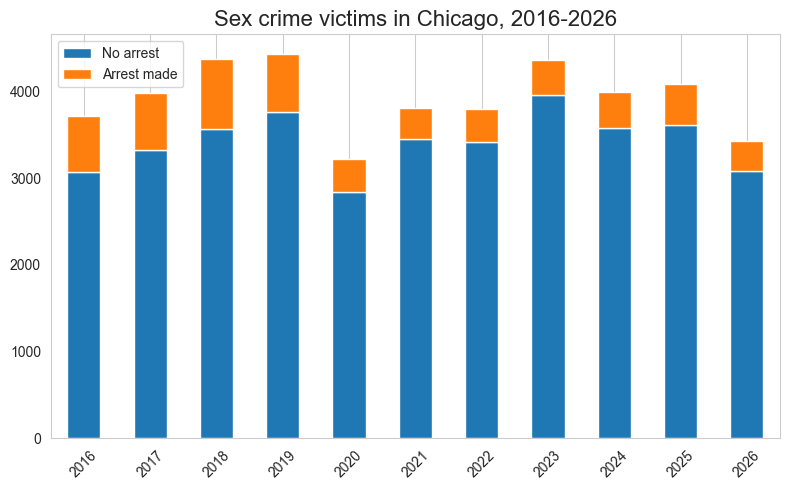

In [9]:
toPlot_1 = gdf.groupby('year')\
    .arrest.value_counts()\
    .unstack()\
    .sort_index()

xfig= 8
yfig= 5

fig, ax= plt.subplots(
    figsize=(xfig, yfig)
)
toPlot_1.plot(
        kind='bar',
        stacked=True,
        ax=ax
        )

ax.set_xlabel('')
ax.set_xticklabels(toPlot_1.index, rotation=45)

ax.grid(axis='y')

ax.legend(
    loc='best',
    labels=['No arrest', 'Arrest made']
)
title_text = 'Sex crime victims in Chicago, 2016-2026'
plt.title(
    title_text,
    fontsize=xfig*2
)

plt.tight_layout()
plt.show()

In [10]:
gdf[gdf.year < '2026-07-01']\
    .arrest.value_counts(normalize=True)

arrest
False    0.87174
True     0.12826
Name: proportion, dtype: float64

In [11]:
# About 11.6 percent of the cases missing geocodes

gdf.longitude.isna().sum() / len(gdf)

np.float64(0.11661922284709204)

In [12]:
# About 3.6 percent block addresses are "unknown"
gdf.block.str.contains('unknown', case=False, na=False).sum() / len(gdf)

np.float64(0.036427596102663794)

In [13]:
missingGeocodes_gdf = gdf[
    (gdf.longitude.isna()) |
    (gdf.latitude.isna())
    ]

print(f'About {
    round(missingGeocodes_gdf.shape[0] / len(gdf), 2) * 100
               } percent of of the reported incidents have missing geocodes ')

print('----')

print(f'Of those, about {
  round(  missingGeocodes_gdf.block.str.contains('unknown', case=False, na=False).sum() / len(missingGeocodes_gdf), 2) *100
} percent having invalid address')

About 12.0 percent of of the reported incidents have missing geocodes 
----
Of those, about 31.0 percent having invalid address


In [14]:
uChicag_adjecent_gdf = gdf[gdf.beat.isin(['0233', '0235'])]

len(uChicag_adjecent_gdf)

266

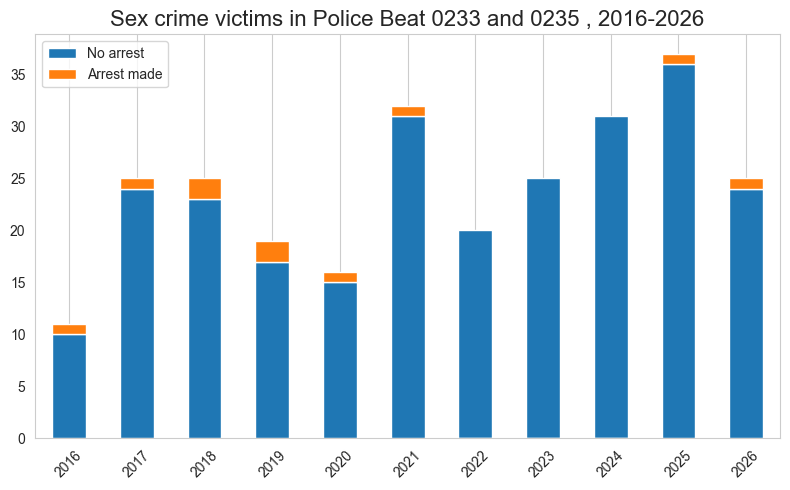

In [15]:
toPlot_2 = uChicag_adjecent_gdf.groupby('year')\
    .arrest.value_counts()\
    .unstack()\
    .sort_index()

xfig= 8
yfig= 5

fig, ax= plt.subplots(
    figsize=(xfig, yfig)
)
toPlot_2.plot(
        kind='bar',
        stacked=True,
        ax=ax
        )

ax.set_xlabel('')
ax.set_xticklabels(toPlot_1.index, rotation=45)

ax.grid(axis='y')

ax.legend(
    loc='best',
    labels=['No arrest', 'Arrest made']
)
title_text = 'Sex crime victims in Police Beat 0233 and 0235 , 2016-2026'
plt.title(
    title_text,
    fontsize=xfig*2
)

plt.tight_layout()
plt.show()

In [16]:
filename = 'transportation_20261029.geojson'
centerline_crosswalk = gpd.read_file(
    f'{supporting_dir}/{filename}'
)

centerline_crosswalk.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 56338 entries, 0 to 56337
Data columns (total 54 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   :id          56338 non-null  object             
 1   :version     56338 non-null  object             
 2   :created_at  56338 non-null  datetime64[ms, UTC]
 3   :updated_at  56338 non-null  datetime64[ms, UTC]
 4   fnode_id     56338 non-null  object             
 5   tnode_id     56338 non-null  object             
 6   objectid     56338 non-null  object             
 7   trans_id     56338 non-null  object             
 8   pre_dir      56002 non-null  object             
 9   street_nam   56002 non-null  object             
 10  street_typ   55198 non-null  object             
 11  suf_dir      2271 non-null   object             
 12  streetname   56338 non-null  object             
 13  l_f_add      56338 non-null  object             
 14  l_t_add      5

In [17]:
block_cols = ['pre_dir', 'street_nam', 'street_typ']

centerline_crosswalk['address_blockName'] = centerline_crosswalk[block_cols].fillna('')\
                                .agg(' '.join, axis=1)\
                                .str.strip()\
                                .str.lower()

range_cols = ['l_f_add', 'l_t_add', 'r_f_add', 'r_t_add']

centerline_crosswalk['address_numRange'] = centerline_crosswalk[range_cols].apply(
    lambda row: range(
        int(row.min()),
        int(row.max()) + 1
    ),
    axis=1
)

centerline_crosswalk.head()

,:id,:version,:created_at,:updated_at,fnode_id,tnode_id,objectid,trans_id,pre_dir,street_nam,street_typ,suf_dir,...,edit_type,flag_strin,ewns_dir,ewns_coord,create_use,create_tim,update_use,update_tim,shape_len,geometry,address_blockName,address_numRange
0,row-6rf7.9kwz.azc9,rv-zh7v.gmj7.z5rf,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,10809,16581,510,127104,S,YALE,AVE,None,...,None,None,W,232,EXISTING,1999-01-01 00:00:00+00:00,EXISTING,1999-01-01 00:00:00+00:00,220.566011733,"MULTILINESTRING ((-87.63187 41.78081, -87.6318...",s yale ave,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
1,row-dvfu_zvgd.q9cw,rv-8qtr_8cuz_cupi,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,6501,34082,511,128895,S,COTTAGE GROVE,AVE,None,...,None,None,None,0,EXISTING,1999-01-01 00:00:00+00:00,EXISTING,1999-01-01 00:00:00+00:00,664.774607336,"MULTILINESTRING ((-87.60549 41.76223, -87.6054...",s cottage grove ave,"(7300, 7301, 7302, 7303, 7304, 7305, 7306, 730..."
2,row-6xpa~w8sg-543u,rv-jgs6.n5wm.hrtt,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,15338,22358,512,142645,S,CAMPBELL,AVE,None,...,None,None,W,2500,EXISTING,1999-01-01 00:00:00+00:00,EXISTING,1999-01-01 00:00:00+00:00,665.378453341,"MULTILINESTRING ((-87.68382 41.69724, -87.6838...",s campbell ave,"(10800, 10801, 10802, 10803, 10804, 10805, 108..."
3,row-vgcw-gjsk_eiai,rv-hpki_n3pa_ry4q,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,15799,28881,513,148189,S,SANGAMON,ST,None,...,None,None,W,932,EXISTING,1999-01-01 00:00:00+00:00,EXISTING,1999-01-01 00:00:00+00:00,152.564966114,"MULTILINESTRING ((-87.64584 41.6934, -87.64624...",s sangamon st,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,..."
4,row-nxmr~7m97~fbdb,rv-yvup_7yk7~3hu5,2021-06-11 21:55:29.795000+00:00,2021-06-11 21:55:29.795000+00:00,36407,36534,514,139728,W,118TH,ST,None,...,None,None,S,11800,EXISTING,1999-01-01 00:00:00+00:00,EXISTING,1999-01-01 00:00:00+00:00,332.691381981,"MULTILINESTRING ((-87.67054 41.67976, -87.6707...",w 118th st,"(1932, 1933, 1934, 1935, 1936, 1937, 1938, 193..."


In [18]:
missingGeocodes_gdf['address_num'] = missingGeocodes_gdf['block'].str.split('XX')\
                                                                .str[0]\
                                                                .agg(lambda x: ''.join(x) + '00')

missingGeocodes_gdf['address_blockName']= missingGeocodes_gdf['block'].str.split('XX')\
                                                                      .str[-1]\
                                                                      .str.strip()\
                                                                      .str.lower()
missingGeocodes_gdf.head()

/var/folders/sm/2p9q9ql94x541dtmhlxn3m400000gs/T/ipykernel_66298/2344980290.py:3: FutureWarning: using <function <lambda> at 0x15f6a2660> in Series.agg cannot aggregate and has been deprecated. Use Series.transform to keep behavior unchanged.
  .agg(lambda x: ''.join(x) + '00')
/Users/kchen/.pyenv/versions/3.12.0/lib/python3.12/site-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/Users/kchen/.pyenv/versions/3.12.0/lib/python3.12/site-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pyd

,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,beat,district,...,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location,dateOnly,yearMonth,geometry,address_num,address_blockName
1,13272025,JG497893,2022-07-07T14:55:00.000,037XX W FULLERTON AVE,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,RESIDENCE - PORCH / HALLWAY,False,False,2525,025,...,None,None,2022,2023-11-10T15:40:55.000,None,None,None,2022-07-07,2022-07,POINT (NaN NaN),03700,w fullerton ave
2,13377016,JH160967,2022-01-01T03:00:00.000,067XX N OLMSTED AVE,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,SIDEWALK,False,False,1612,016,...,None,None,2022,2024-02-23T15:41:55.000,None,None,None,2022-01-01,2022-01,POINT (NaN NaN),06700,n olmsted ave
3,12296301,JE146058,2020-12-04T01:00:00.000,028XX W JACKSON BLVD,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,ALLEY,False,False,1124,011,...,None,None,2020,2021-02-20T15:40:21.000,None,None,None,2020-12-04,2020-12,POINT (NaN NaN),02800,w jackson blvd
4,13484371,JH291551,2023-01-05T15:00:00.000,055XX N KENMORE AVE,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,HOSPITAL BUILDING / GROUNDS,False,False,2023,020,...,None,None,2023,2024-06-06T15:41:55.000,None,None,None,2023-01-05,2023-01,POINT (NaN NaN),05500,n kenmore ave
6,14168268,JK219134,2017-01-01T00:00:00.000,020XX N SEDGWICK ST,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,APARTMENT,False,False,1814,018,...,None,None,2017,2026-04-16T15:45:49.000,None,None,None,2017-01-01,2017-01,POINT (NaN NaN),02000,n sedgwick st


In [19]:
centerline_crosswalk.columns

Index([':id', ':version', ':created_at', ':updated_at', 'fnode_id', 'tnode_id',
       'objectid', 'trans_id', 'pre_dir', 'street_nam', 'street_typ',
       'suf_dir', 'streetname', 'l_f_add', 'l_t_add', 'r_f_add', 'r_t_add',
       'logiclf', 'logiclt', 'logicrf', 'logicrt', 'class', 'status',
       'status_dat', 'tiered', 'oneway_dir', 'dir_travel', 'ewns', 'l_parity',
       'r_parity', 'f_zlev', 't_zlev', 'l_fips', 'r_fips', 'r_zip', 'l_zip',
       'r_censusbl', 'l_censusbl', 'f_cross', 'f_cross_st', 't_cross',
       't_cross_st', 'length', 'edit_date', 'edit_type', 'flag_strin',
       'ewns_dir', 'ewns_coord', 'create_use', 'create_tim', 'update_use',
       'update_tim', 'shape_len', 'geometry', 'address_blockName',
       'address_numRange'],
      dtype='object')

In [20]:
def in_range(num, rng):
    try:
        return int(num) in rng
    except (ValueError, TypeError):
        return False



in_range(1, range(4, 15))

False

In [21]:
missing = missingGeocodes_gdf.copy()
missing["mg_id"] = range(len(missing))

# 1) Merge on block name
merged = missing.merge(
    centerline_crosswalk,
    on="address_blockName",
    how="inner",
    suffixes=("", "_cl"),
)

def in_range(num, rng):
    try:
        return int(num) in rng
    except (ValueError, TypeError):
        return False

keep_rows = []

for num, rng in zip(merged["address_num"], merged["address_numRange"]):
    try:
        keep_rows.append(int(num) in rng)
    except (ValueError, TypeError):
        keep_rows.append(False)

merged = merged[keep_rows]

# 3) One match per address: keep the tightest range
merged = (
    merged.assign(range_width=merged["address_numRange"].map(len))
          .sort_values(["mg_id", "range_width"])
          .drop_duplicates("mg_id", keep="first")
          .drop(columns="range_width")
)

# 4) Result as a GeoDataFrame (centerline geometry active; use "geometry" to keep the points)
matched = gpd.GeoDataFrame(merged, geometry="geometry_cl", crs=centerline_crosswalk.crs)

# 5) Unmatched rows and match rate
unmatched = missing[~missing["mg_id"].isin(matched["mg_id"])]
print(f"Match rate: {len(matched) / len(missing):.1%}")

Match rate: 67.1%


In [ ]:
# drop those rows and replace from matched

gdf= gdf[~(gdf.id.isin(matched.id))]


matched_partialCols = matched[
    matched.columns[matched.columns.isin(gdf.columns)]]

gdf= pd.concat(
    [gdf, matched_partialCols]

gdf['approximate_coordinate'] = 'no'
gdf.loc[matched_partialCols.index, 'approximate_coordinate'] = 'yes'

In [33]:
school_keywords = ['university', 'college','school']

uni_college_school_gdf= gdf[gdf.location_description.str.contains('|'.join(school_keywords), case=False, na=False)]

uni_college_school_gdf.year.value_counts().sort_index()

year
2016    125
2017    129
2018    181
2019    182
2020     59
2021    103
2022    141
2023    133
2024    144
2025     89
2026     84
Name: count, dtype: int64

In [34]:
uni_college_school_gdf[
    uni_college_school_gdf.location_description.str.contains(
        'university', na=False, case=False
    )
].to_crs(epsg=4326)

uni_college_school_gdf= uni_college_school_gdf[~(uni_college_school_gdf.longitude.isna())]
uni_college_school_gdf

,id,case_number,date,block,iucr,primary_type,description,location_description,arrest,domestic,beat,district,...,fbi_code,x_coordinate,y_coordinate,year,updated_on,latitude,longitude,location,dateOnly,yearMonth,geometry,approximate_coordinate
111,10586951,HZ337425,2016-07-05T02:00:00.000,091XX S UNIVERSITY AVE,0261,CRIM SEXUAL ASSAULT,AGGRAVATED: HANDGUN,"SCHOOL, PUBLIC, GROUNDS",False,False,0413,004,...,02,1185475,1844606,2016,2018-02-10T15:50:01.000,41.728740563,-87.596150779,"{'human_address': '{""address"": """", ""city"": """",...",2016-07-05,2016-07,POINT (-87.59615 41.72874),no
156,10837948,JA140193,2017-02-01T14:50:00.000,081XX S SOUTH CHICAGO AVE,0261,CRIM SEXUAL ASSAULT,AGGRAVATED: HANDGUN,"SCHOOL, PUBLIC, GROUNDS",False,True,0414,004,...,02,1190162,1851155,2017,2017-02-14T15:49:42.000,41.746600212,-87.578771154,"{'human_address': '{""address"": """", ""city"": """",...",2017-02-01,2017-02,POINT (-87.57877 41.7466),yes
610,13958229,JJ403825,2025-09-05T13:00:00.000,048XX W ERIE ST,0261,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - HANDGUN,SCHOOL - PRIVATE GROUNDS,False,False,1532,015,...,02,1143890,1903875,2025,2026-03-14T15:41:39.000,41.892260249,-87.747006374,"{'human_address': '{""address"": """", ""city"": """",...",2025-09-05,2025-09,POINT (-87.74701 41.89226),no
766,11361432,JB324528,2018-06-27T02:00:00.000,104XX S STATE ST,0263,CRIM SEXUAL ASSAULT,AGGRAVATED: KNIFE/CUT INSTR,"SCHOOL, PUBLIC, GROUNDS",False,False,0512,005,...,02,1178091,1835934,2018,2018-07-04T15:53:35.000,41.705113794,-87.623461757,"{'human_address': '{""address"": """", ""city"": """",...",2018-06-27,2018-06,POINT (-87.62346 41.70511),no
886,13044811,JG226614,2023-03-23T08:00:00.000,038XX N NEW ENGLAND AVE,0263,CRIMINAL SEXUAL ASSAULT,AGGRAVATED - KNIFE / CUTTING INSTRUMENT,SCHOOL - PUBLIC BUILDING,False,False,1632,016,...,02,1129719,1924648,2023,2024-10-01T15:40:39.000,41.949517926,-87.798575692,"{'human_address': '{""address"": """", ""city"": """",...",2023-03-23,2023-03,POINT (-87.79858 41.94952),no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43032,11921959,JC547287,2019-12-14T21:30:00.000,061XX S WOLCOTT AVE,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,SCHOOL - PUBLIC BUILDING,False,False,0714,007,...,17,1164741,1863948,2019,2020-04-08T15:41:11.000,41.782279941,-87.671559063,"{'human_address': '{""address"": """", ""city"": """",...",2019-12-14,2019-12,POINT (-87.67156 41.78228),no
43082,12517532,JE416352,2021-10-13T10:00:00.000,078XX S PRAIRIE AVE,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,SCHOOL - PUBLIC GROUNDS,False,False,0623,006,...,17,1179391,1853086,2021,2022-03-10T15:56:11.000,41.752151511,-87.618179506,"{'human_address': '{""address"": """", ""city"": """",...",2021-10-13,2021-10,POINT (-87.61818 41.75215),no
43094,12675986,JF214095,2022-04-19T15:45:00.000,026XX S LAWNDALE AVE,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,SCHOOL - PUBLIC BUILDING,False,False,1031,010,...,17,1152130,1886238,2022,2023-01-03T15:40:27.000,41.843703836,-87.717208988,"{'human_address': '{""address"": """", ""city"": """",...",2022-04-19,2022-04,POINT (-87.71721 41.8437),no
43127,13070686,JG257713,2023-05-12T07:00:00.000,0000X W MONROE ST,5004,SEX OFFENSE,ATTEMPT CRIMINAL SEXUAL ABUSE,SCHOOL - PUBLIC GROUNDS,False,False,0112,001,...,17,1175721,1899903,2023,2023-08-19T15:40:26.000,41.880704482,-87.630224558,"{'human_address': '{""address"": """", ""city"": """",...",2023-05-12,2023-05,POINT (-87.63022 41.8807),no


In [39]:
approximate_gdf = gdf[gdf.approximate_coordinate == 'yes']

len(approximate_gdf)

3910

In [40]:
import folium
from branca.element import MacroElement, Template


class YearSlider(MacroElement):
    """Slider that shows one year at a time (position 0 = all years) across several parent layers."""
    _template = Template("""
    {% macro html(this, kwargs) %}
    <div style="position:fixed; bottom:30px; left:50%; transform:translateX(-50%);
                z-index:9999; background:white; padding:10px 16px; border-radius:6px;
                box-shadow:0 1px 5px rgba(0,0,0,.4); font-family:sans-serif; width:420px;">
      <div style="display:flex; align-items:center; gap:10px;">
        <button id="year-play" style="cursor:pointer;">&#9654;</button>
        <input type="range" id="year-slider" min="0" max="{{ this.n_years }}"
               value="{{ this.initial_pos }}" step="1" style="flex:1;">
        <b id="year-label" style="min-width:60px; text-align:right;">All</b>
      </div>
    </div>
    {% endmacro %}

    {% macro script(this, kwargs) %}
    (function () {
        var years = {{ this.years_json }};
        var parents = [{{ this.parent_names }}];
        var children = {{ this.children_js }};
        var slider = document.getElementById("year-slider");
        var label = document.getElementById("year-label");
        var playBtn = document.getElementById("year-play");
        var timer = null;

        function update(pos) {
            parents.forEach(function (parent, d) {
                children[d].forEach(function (child, i) {
                    var visible = (pos === 0) || (i === pos - 1);
                    if (visible && !parent.hasLayer(child)) { parent.addLayer(child); }
                    if (!visible && parent.hasLayer(child)) { parent.removeLayer(child); }
                });
            });
            label.textContent = pos === 0 ? "2016-2026" : years[pos - 1];
        }

        slider.addEventListener("input", function () { update(parseInt(slider.value)); });

        playBtn.addEventListener("click", function () {
            if (timer) {
                clearInterval(timer); timer = null; playBtn.innerHTML = "&#9654;";
                return;
            }
            playBtn.innerHTML = "&#10074;&#10074;";
            timer = setInterval(function () {
                var next = parseInt(slider.value) + 1;
                if (next > years.length) { next = 1; }
                slider.value = next;
                update(next);
            }, 1000);
        });

        update({{ this.initial_pos }});
    })();
    {% endmacro %}
    """)

    def __init__(self, parents, children_by_parent, years, initial_year=None):
        super().__init__()
        self._name = "YearSlider"
        self.parent_names = ",".join(p.get_name() for p in parents)
        self.children_js = "[" + ",".join(
            "[" + ",".join(c.get_name() for c in kids) + "]"
            for kids in children_by_parent
        ) + "]"
        self.years_json = str([int(y) for y in years])
        self.n_years = len(years)

        # Slider position: 0 = All, otherwise 1-based index into years
        years_int = [int(y) for y in years]
        if initial_year is not None and int(initial_year) in years_int:
            self.initial_pos = years_int.index(int(initial_year)) + 1
        else:
            self.initial_pos = 0


def clean(df):
    """Drop rows with no year and make year an integer."""
    df = df.dropna(subset=["year"]).copy()
    df["year"] = df["year"].astype(int)
    return df


def add_layer(m, df, layer_name, years, radius):
    """Create a parent layer with one child group per year and fill it with markers."""
    parent = folium.FeatureGroup(
        name=layer_name, overlay=True, control=True, show=True
    ).add_to(m)
    children = [
        folium.FeatureGroup(name=str(y), control=False).add_to(parent)
        for y in years
    ]
    child_by_year = dict(zip(years, children))

    for _, row in df.iterrows():
        point = row.geometry.representative_point()
        marker_color = "firebrick" if row["arrest"] == True else "blue"

        tooltip_html = (
            f"<b>Date:</b> {row['dateOnly']}<br>"
            f"<b>Type:</b> {row['primary_type']}<br>"
            f"<b>Location description:</b> {row['location_description']}<br>"
            f"<b>Case #:</b> {row['case_number']}<br>"
            f"<b>Arrest:</b> {row['arrest']}"
        )

        folium.CircleMarker(
            location=[point.y, point.x],
            radius=radius,
            color=marker_color,
            fill=True,
            fill_color=marker_color,
            fill_opacity=0.6,
            tooltip=folium.Tooltip(tooltip_html, sticky=True),
        ).add_to(child_by_year[row["year"]])

    return parent, children


# ---------------- Build map (top level, no indentation) ----------------
gdf_clean = clean(gdf)
uni_clean = clean(uni_college_school_gdf)
approximate_clean = clean(approximate_gdf)

# Shared year list so the slider lines up across both layers
years = sorted(set(gdf_clean["year"]) | set(uni_clean["year"]))

m = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles=None)

folium.plugins.Geocoder().add_to(m)

folium.TileLayer(
    tiles=(
        "https://basemaps.cartocdn.com/rastertiles/light_all/"
        "{z}/{x}/{y}.png"
        "?key=cb1_3t1q_1_0960046504f90cb9125e4501"
    ),
    attr="© OpenStreetMap contributors © CARTO",
    name="Chicago",
    overlay=True,
    control=False,
    show=True,
).add_to(m)

# Layer 1: all crimes (drawn first, underneath)
all_parent, all_children = add_layer(
    m, gdf_clean, "All reported sex crimes", years, radius=5
)

# Layer 2: university / college / school subset (drawn on top, larger)
uni_parent, uni_children = add_layer(
    m, uni_clean, "Reported sex crimes on college or school grounds", years, radius=5
)

# Layer 3: For those with missing but processed coordinates

uni_parent, uni_children = add_layer(
    m, approximate_clean, "Rported sex crimes but with missing coordiantes", years, radius=5
)

folium.LayerControl(collapsed=False).add_to(m)

# Slider LAST so the layer variables already exist in the page script
YearSlider(
    parents=[all_parent, uni_parent],
    children_by_parent=[all_children, uni_children],
    years=years,
    initial_year=2026,
).add_to(m)

filename = "all_sexualCrimes_timeline"
output_path = f"{viz_dir}/{filename}.html"
m.save(output_path)

In [37]:
filename = 'chicago_police_hospital_geocodes'

police_hospital_df= pd.read_csv(
    f'{raw_dir}/{filename}.csv',
    index_col=0
)
police_hospital_df= police_hospital_df[['district', 'name', 'main_type', 
                                        'address', 'latitude', 'longitude']]

police_hospital_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60 entries, 0 to 200
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   district   23 non-null     object 
 1   name       60 non-null     object 
 2   main_type  60 non-null     object 
 3   address    60 non-null     object 
 4   latitude   60 non-null     float64
 5   longitude  60 non-null     float64
dtypes: float64(2), object(4)
memory usage: 3.3+ KB


In [38]:
police_hospital_gdf = gpd.GeoDataFrame(
    police_hospital_df, 
    geometry=gpd.points_from_xy(
            police_hospital_df['longitude'],
            police_hospital_df['latitude']
        ),
        crs='EPSG:4326'
    )

police_hospital_gdf

,district,name,main_type,address,latitude,longitude,geometry
0,Headquarters,Headquarters,police,3510 S Michigan Ave,41.830702,-87.623395,POINT (-87.6234 41.8307)
1,18,Near North,police,1160 N Larrabee St,41.903242,-87.643352,POINT (-87.64335 41.90324)
2,19,Town Hall,police,850 W Addison St,41.947400,-87.651512,POINT (-87.65151 41.9474)
3,20,Lincoln,police,5400 N Lincoln Ave,41.979550,-87.692845,POINT (-87.69284 41.97955)
4,22,Morgan Park,police,1900 W Monterey Ave,41.691435,-87.668520,POINT (-87.66852 41.69143)
...,...,...,...,...,...,...,...
192,NaN,The University of Chicago Medical Center,hospital,5841 S Maryland Ave MC 1000,41.788439,-87.604283,POINT (-87.60428 41.78844)
194,NaN,Thorek Memorial Hospital,hospital,850 West Irving Park Rd,41.954822,-87.651283,POINT (-87.65128 41.95482)
195,NaN,Thorek Memorial Hospital - DBA Thorek Memorial...,hospital,5025 N Paulina Street,41.972722,-87.671276,POINT (-87.67128 41.97272)
199,NaN,UHS Hartgrove Hospital,hospital,5730 W Roosevelt Rd,41.866343,-87.767437,POINT (-87.76744 41.86634)
